## Лабораторная работа №1 | Вариант 6

Выполнил: Брежнев Георгий М8О-312БВ-24

### 1. Numpy

In [1]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [2]:
np.eye(3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

2. Создайте матрицу 5х5 со значениями 1, 2, 3, 4 ниже диагонали

In [3]:
np.diag([1, 2, 3, 4], k=-1)

array([[0, 0, 0, 0, 0],
       [1, 0, 0, 0, 0],
       [0, 2, 0, 0, 0],
       [0, 0, 3, 0, 0],
       [0, 0, 0, 4, 0]])

3. Какой выход будет у данного скрипта

```python
# Author: Jake VanderPlas

print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))
```

In [ ]:
9 # Начальная сумма = -1, -1+0+1+2+3+4=9
10 # Функция sum теперь из numpy, там вторым
#аргументом является ось, вдоль которой
#значения суммируются


4. Как найти самое часто встречаемое значение между двумя массивами? 

In [5]:
a = np.array([1, 2, 2, 3, 4, 4, 4])
b = np.array([2, 2, 4, 4, 5])

# Оставляем только значения, которые есть в обоих массивах
common = np.intersect1d(a, b)
# Считаем, сколько раз каждое из них встречается в объединенном массиве
all_values = np.concatenate((a, b))
counts = np.array([np.sum(all_values == value) for value in common])

common[np.argmax(counts)]


np.int64(4)

5. Как игнорировать все warnings в numpy(не нужно так делать, но покажи)?

In [6]:
np.seterr(all='ignore')
print(np.array([5.0]) / 0)
np.seterr(all='warn')
print(np.array([5.0]) / 0)

[inf]
[inf]


/tmp/ipykernel_37379/2382282629.py:4: RuntimeWarning: divide by zero encountered in divide
  print(np.array([5.0]) / 0)


6. Реализуем функцию-генератор, которая генерирует 10 целых чисел и используем ее для построения массива

In [7]:
def make_numbers():
    for i in range(10):
        yield i

np.fromiter(make_numbers(), dtype=int)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

7. Создайте массив случайных чисел размером 10 и отсортируйте его

In [8]:
numbers = np.random.rand(10)
numbers.sort()
numbers

array([0.04935056, 0.2287659 , 0.23336504, 0.27932225, 0.32678294,
       0.35035828, 0.42770823, 0.44103306, 0.94812495, 0.96191755])

8. Создайте случайную матрицу 10х2 которая представляет собой декартовые координаты и преобразуйте их в полярные

In [9]:
points = np.random.uniform(-1, 1, (10, 2))
x = points[:, 0]
y = points[:, 1]

r = np.sqrt(x ** 2 + y ** 2)
angle = np.arctan2(y, x)

polar = np.column_stack((r, angle))
polar

array([[ 0.86826094, -0.92815699],
       [ 0.46482359, -1.56051703],
       [ 0.68534534, -1.58054504],
       [ 1.06802216,  0.89790801],
       [ 0.28735239,  1.83333557],
       [ 0.78056432,  3.02450943],
       [ 0.9543709 ,  0.19874637],
       [ 0.74299888, -2.00074937],
       [ 0.25678064, -3.00715152],
       [ 0.68567656, -2.4766433 ]])

9. Создайте структурированный массив который будет описывать пиксель(координату x, y и цвет r,g,b)

In [10]:
pixel_type = np.dtype([
    ('x', np.int32),
    ('y', np.int32),
    ('r', np.uint8),
    ('g', np.uint8),
    ('b', np.uint8)
])

pixels = np.array([(25, 50, 255, 77, 77), (30, 40, 0, 128, 255)], dtype=pixel_type)
pixels

array([(25, 50, 255,  77,  77), (30, 40,   0, 128, 255)],
      dtype=[('x', '<i4'), ('y', '<i4'), ('r', 'u1'), ('g', 'u1'), ('b', 'u1')])

10. Как конвертировать тип массив от float32 в int32 in place?

In [11]:
a = np.array([1.5, 2.7, -3.2, 4.0], dtype=np.float32)

int_view = a.view(np.int32)
int_view[:] = a.astype(np.int32)

print(int_view)
print(int_view.dtype)


[ 1  2 -3  4]
int32


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Набор данных описывает эффективность учеников в зависимости от некоторых факторов влияющих на обучение и окружение человека.

Файл: `student_perfomance.csv`

```
Hours_Studied - количество часов затраченное на обучение в неделю
Attendance - поцент посещенных занятий
Parental_Involvement - уровень участия родителей в обучении учащегося
Access_to_Resources - доступность ресурсов для обучения
Extracurricular_Activities - участие во внеклассных мероприятиях
Sleep_Hours - количество часов выделяемое на сон в день
Previous_Scores - оценка за первый экзамен
Motivation_Level - уровень мотивации
Internet_Access - доступ к интернету
Tutoring_Sessions - количество посещаемых репетиторских занятий в месяц.
Family_Income - доход семьи
Teacher_Quality - насколько качественно преподает учитель
School_Type - тип школы(частная, обычная)
Peer_Influence - влияние сверстников
Physical_Activity - физическая активность
Learning_Disabilities - наличие проблем с обучаемостью
Parental_Education_Level - уровень образования родителей
Distance_from_Home - дистанция от дома до школы
Gender - пол
Exam_Score - оценка на конечном экзамене
```

In [12]:
import pandas as pd

In [13]:
# Load dataset here
df = pd.read_csv('student_perfomance.csv')
df.head(10)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
5,19,88,Medium,Medium,Yes,8,89,Medium,Yes,3,Medium,Medium,Public,Positive,3,No,Postgraduate,Near,Male,71
6,29,84,Medium,Low,Yes,7,68,Low,Yes,1,Low,Medium,Private,Neutral,2,No,High School,Moderate,Male,67
7,25,78,Low,High,Yes,6,50,Medium,Yes,1,High,High,Public,Negative,2,No,High School,Far,Male,66
8,17,94,Medium,High,No,6,80,High,Yes,0,Medium,Low,Private,Neutral,1,No,College,Near,Male,69
9,23,98,Medium,Medium,Yes,8,71,Medium,Yes,0,High,High,Public,Positive,5,No,High School,Moderate,Male,72


1. Посчитайте среднее кол-во часов уделяемое на сон студентами

In [14]:
df['Sleep_Hours'].mean()

np.float64(7.029060087785682)

2. Сколько процентов студентов посещают внеклассовые активности?

In [15]:
(df['Extracurricular_Activities'] == 'Yes').mean() * 100

np.float64(59.60345088542455)

3. Правда ли, что в среднем девушки сдают экзамены лучше, чем мужчины

In [16]:
gender_mean = df.groupby('Gender')['Exam_Score'].mean()
print(gender_mean)

if gender_mean['Female'] > gender_mean['Male']:
    print('Да')
else:
    print('Нет')

Gender
Female    67.244898
Male      67.228894
Name: Exam_Score, dtype: float64
Да


4. Выведите 25 и 75 перцентили времени сна студентов

In [17]:
df['Sleep_Hours'].quantile([0.25, 0.75])

0.25    6.0
0.75    8.0
Name: Sleep_Hours, dtype: float64

5. Правда ли, что те, кто спит больше(75 перцентиль и выше) сдает экзамен лучше, чем студенты с недосыпом(25 перцентиль и меньше)

In [18]:
q25 = df['Sleep_Hours'].quantile(0.25)
q75 = df['Sleep_Hours'].quantile(0.75)

sleep_more = df.loc[df['Sleep_Hours'] >= q75, 'Exam_Score'].mean()
sleep_less = df.loc[df['Sleep_Hours'] <= q25, 'Exam_Score'].mean()

print('Средний балл тех, кто спит больше:', sleep_more)
print('Средний балл тех, кто спит меньше:', sleep_less)

if sleep_more > sleep_less:
    print('Да')
else:
    print('Нет')

Средний балл тех, кто спит больше: 67.18704746580853
Средний балл тех, кто спит меньше: 67.28109243697479
Нет


6. Влияет ли физическая активность на результаты экзамена?

In [19]:
print('Корреляция:', df['Physical_Activity'].corr(df['Exam_Score']))
df.groupby('Physical_Activity')['Exam_Score'].agg(['mean', 'count'])

Корреляция: 0.02782443618025734


,mean,count
Physical_Activity,,
0,67.521739,46
1,66.969121,421
2,67.185003,1627
3,67.196071,2545
4,67.313016,1575
5,67.603878,361
6,68.093750,32


7. Правда ли, что слуденты, чьи родители имеют высшее образование(College || Postgraduate), сдают экзамены лучше, чем остальные?

In [20]:
valid = df.dropna(subset=['Parental_Education_Level'])
higher = valid['Parental_Education_Level'].isin(['College', 'Postgraduate'])

higher_mean = valid.loc[higher, 'Exam_Score'].mean()
other_mean = valid.loc[~higher, 'Exam_Score'].mean()

print('College и Postgraduate:', higher_mean)
print('Остальные:', other_mean)

if higher_mean > other_mean:
    print('Да')
else:
    print('Нет')

College и Postgraduate: 67.57528840315726
Остальные: 66.89357741234875
Да


8. Как влияет участие родителей на результаты экзаменов

In [21]:
df.groupby('Parental_Involvement')['Exam_Score'].mean().reindex(['Low', 'Medium', 'High'])

Parental_Involvement
Low       66.358265
Medium    67.098156
High      68.092767
Name: Exam_Score, dtype: float64

9. Правда ли, что в семьях с доходом больше среднего дети сдают экзамены лучше?

In [22]:
high_income_mean = df.loc[df['Family_Income'] == 'High', 'Exam_Score'].mean()
other_income_mean = df.loc[df['Family_Income'] != 'High', 'Exam_Score'].mean()

print('Доход High:', high_income_mean)
print('Остальные доходы:', other_income_mean)

if high_income_mean > other_income_mean:
    print('Да')
else:
    print('Нет')

Доход High: 67.84239558707644
Остальные доходы: 67.09142000749344
Да


10. Посчитайте долю студентов сдавших экзамен на более чем 70 баллов в семьях с низким доходом и отсутствием доступа к интернету

In [23]:
group = df[(df['Family_Income'] == 'Low') & (df['Internet_Access'] == 'No')]
(group['Exam_Score'] > 70).mean() * 100

np.float64(8.056872037914692)

### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Правда ли, что количество часов затрачиваемых на сон распределено примерно нормально?

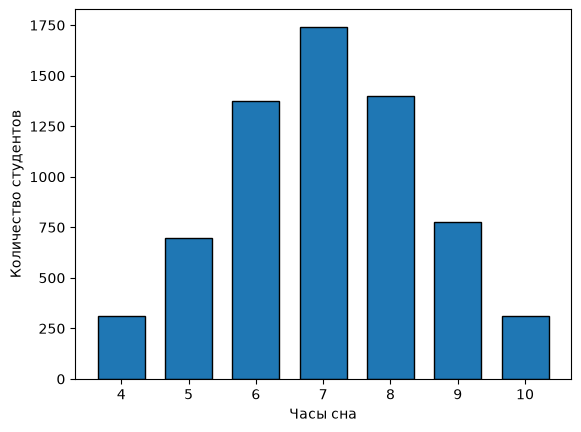

Асимметрия: -0.02380543688615691
Да


In [24]:
import matplotlib.pyplot as plt

sleep = df['Sleep_Hours'].dropna()

plt.hist(sleep, bins=np.arange(3.5, 11.5), edgecolor='black', rwidth=0.7)
plt.xlabel('Часы сна')
plt.ylabel('Количество студентов')
plt.show()

print('Асимметрия:', sleep.skew())
if abs(sleep.skew()) < 0.5:
    print('Да')
else:
    print('Нет')

2. Постройте гистограмму распределения количества часов затрачиваемых на обучение среди мальчиков и девочек

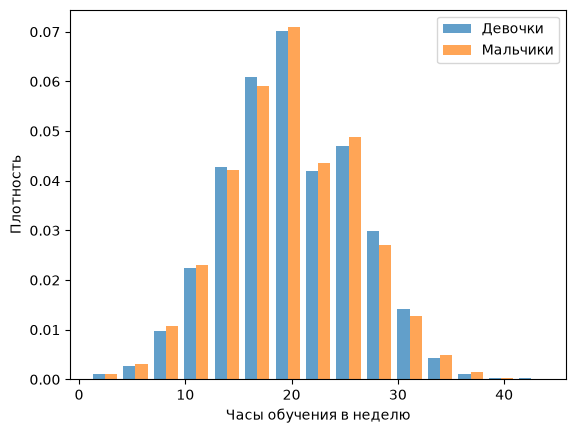

In [25]:
girls = df.loc[df['Gender'] == 'Female', 'Hours_Studied']
boys = df.loc[df['Gender'] == 'Male', 'Hours_Studied']

plt.hist([girls, boys], bins=15, alpha=0.7, label=['Девочки', 'Мальчики'], density=True)
plt.xlabel('Часы обучения в неделю')
plt.ylabel('Плотность')
plt.legend()
plt.show()

3. Как зависит результат конечного экзамена от результата первого экзамена

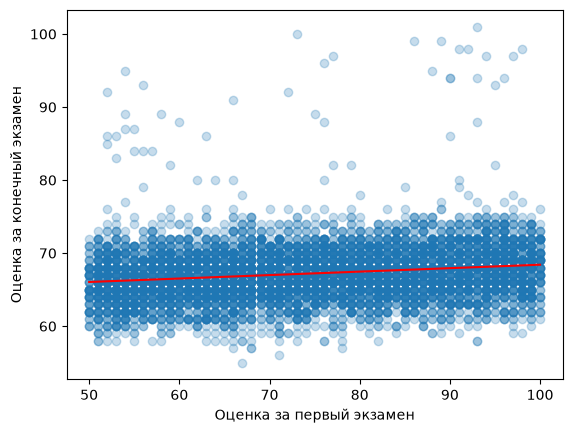

In [26]:
plt.scatter(df['Previous_Scores'], df['Exam_Score'], alpha=0.25)
k, b = np.polyfit(df['Previous_Scores'], df['Exam_Score'], 1)
x = np.array([df['Previous_Scores'].min(), df['Previous_Scores'].max()])
plt.plot(x, k * x + b, color='red')
plt.xlabel('Оценка за первый экзамен')
plt.ylabel('Оценка за конечный экзамен')
plt.show()

4. Постройте box plot отображающий распределение количества сна детей сдавших экзамены на оценку ниже и выше 85 баллов

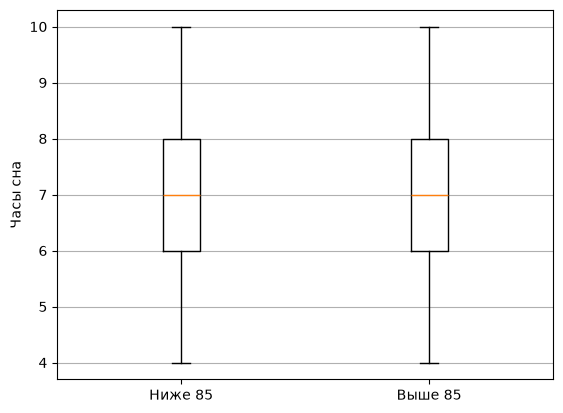

In [27]:
low = df[df['Exam_Score'] < 85]['Sleep_Hours']
high = df[df['Exam_Score'] > 85]['Sleep_Hours']

plt.boxplot([low, high], tick_labels=['Ниже 85', 'Выше 85'])
plt.ylabel('Часы сна')
plt.grid(axis='y')
plt.show()

5. Правда ли, что количество посещаемых занятий с репетитором в месяц напрямую влияет на балл в конечном экзамене?

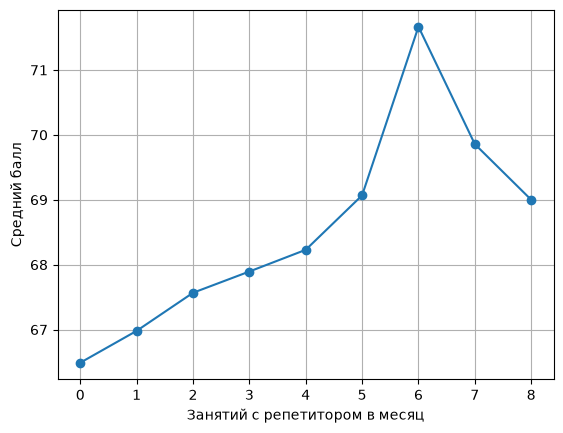

Корреляция: 0.157
Нет


In [28]:
mean_scores = df.groupby('Tutoring_Sessions')['Exam_Score'].mean()

mean_scores.plot(marker='o')
plt.xlabel('Занятий с репетитором в месяц')
plt.ylabel('Средний балл')
plt.grid(True)
plt.show()

r = df['Tutoring_Sessions'].corr(df['Exam_Score'])
print('Корреляция:', round(r, 3))
print('Да' if abs(r) >= 0.3 else 'Нет')

6. Как физическая активность влияет на успеваемость?

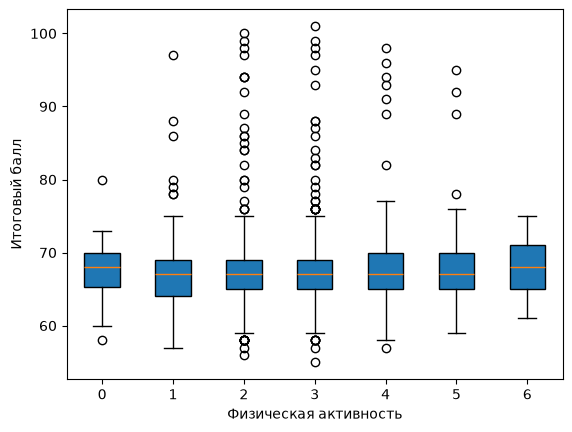

In [29]:
levels = sorted(df['Physical_Activity'].dropna().unique())

data = []
for lvl in levels:
    data.append(df[df['Physical_Activity'] == lvl]['Exam_Score'])

plt.boxplot(data, tick_labels=levels, patch_artist=True)
plt.xlabel('Физическая активность')
plt.ylabel('Итоговый балл')
plt.show()

7. Постройте HeatMap где ось Х - процент посещаемость, Y - количество занятий с репетитором, а Z - балл за итоговый экзамен*

\* Задание на доп. балл

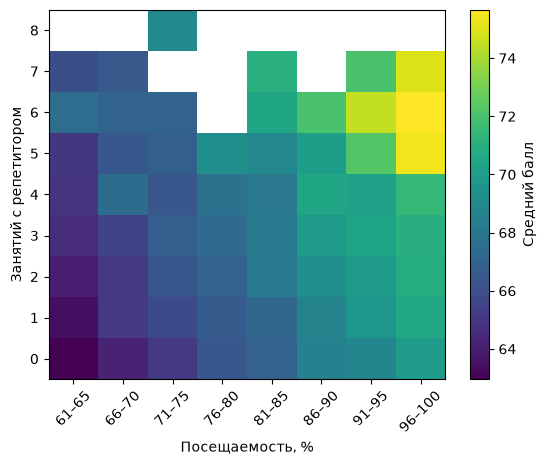

In [30]:
step = 5
start = int(df['Attendance'].min() // step * step)

edges = np.arange(start, 100 + 1, step)
names = [f'{a + 1}–{a + step}' for a in edges[:-1]]

df['att_group'] = pd.cut(df['Attendance'], bins=edges, labels=names, right=True, include_lowest=True)
table = df.groupby(['Tutoring_Sessions', 'att_group'], observed=False)['Exam_Score'].mean().unstack()

plt.imshow(table, origin='lower', aspect='auto')
plt.colorbar(label='Средний балл')
plt.xticks(range(len(table.columns)), table.columns, rotation=45)
plt.yticks(range(len(table.index)), table.index)
plt.xlabel('Посещаемость, %')
plt.ylabel('Занятий с репетитором')
plt.show()